# Exercício 1: Teorema Central do Limite

Considere o **Teorema Central do Limite (TCL)**. Sejam $X_1, \ldots, X_n$ variáveis aleatórias i.i.d., com média $\mu$ e variância finita $\sigma^2$. Então,

$$
\frac{\sqrt{n}(\bar{X}_n - \mu)}{\sigma}
\xrightarrow{d}
N(0,1),
$$

quando $n \to \infty$.

O objetivo deste exercício é verificar empiricamente o comportamento descrito pelo TCL para diferentes distribuições e diferentes valores de $n$.

1. Considere as seguintes distribuições para $X$:

   * Uniforme;
   * Bernoulli;
   * Geométrica;
   * Poisson.

   Para cada distribuição, escolha diferentes valores de $n$ e gere $M = 5000$ realizações da variável aleatória

   $$
   Z_n = \frac{\sqrt{n}(\bar{X}_n - \mu)}{\sigma}.
   $$

   Compare o comportamento da distribuição de $Z_n$ conforme o valor de $n$ aumenta.

2. Para cada distribuição e para cada valor de $n$, construa um histograma das $M = 5000$ realizações de $Z_n$.

   Compare os histogramas obtidos com uma amostra de uma distribuição normal padrão $N(0,1)$ gerada diretamente pelo NumPy.

3. Analise os resultados obtidos e discuta:

   * como a aproximação pela distribuição normal muda conforme $n$ aumenta;
   * quais distribuições apresentam convergência mais rápida para a normal;
   * como o formato da distribuição original influencia a qualidade da aproximação para valores pequenos de $n$.


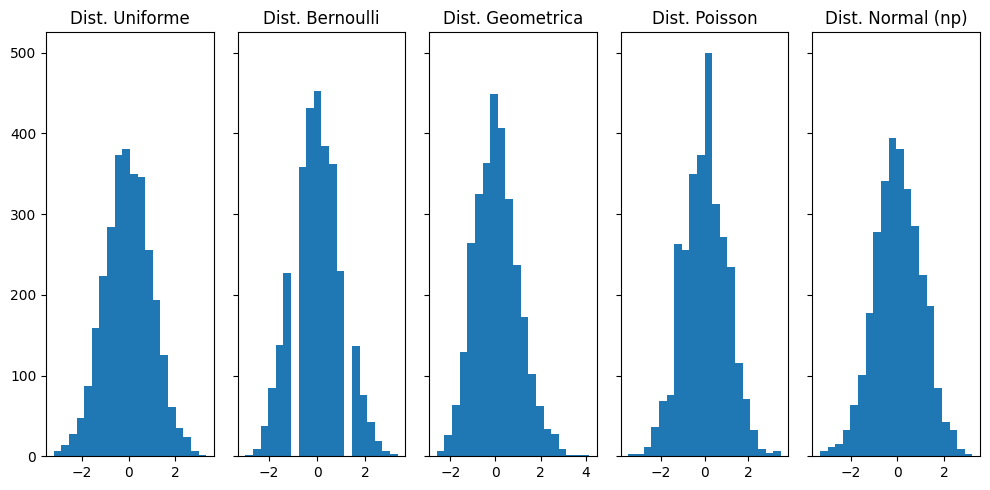

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


M = 3000
n_amostra = 30

p_bernoulli = 0.4
p_geometrica = 0.6
lambda_poisson = 3

parametros_teoricos_uniforme = ((0.5), (1/12))
parametros_teoricos_bernoulli = ((p_bernoulli), (p_bernoulli * (1 - p_bernoulli)))
parametros_teoricos_geometrica = ((1/p_geometrica), ((1 - p_geometrica)/(p_geometrica ** 2)))
parametros_teoricos_poisson = (lambda_poisson, lambda_poisson)

def amostraRecursivaGeometrica(n, M, p):
  x = [] # amostra final
  for _ in range(M):
    u = np.random.uniform(0,1, size = n)
    x.append(np.floor(np.log(1 - u)/np.log(1 - p)) + 1)
  return x

def amostraBernoulliIngenua(n, M, p):
    u = np.random.uniform(0, 1, size=(M, n)) # retorna um array de valores

    return (p > u)

def amostraUniforme(n, M):
  return np.random.uniform(0,1, size=(M, n))

def amostraPoissonRecursivo(n, M, lmd): # TODO: é possível vetorizar essa função?
  amostra_pois = []
  for _ in range(M):
    amostra = []
    for _ in range(n):
      u = np.random.uniform(0,1)

      i = 0
      pi = np.exp((-lmd))
      F = pi
      while u > F:
        i+=1
        pi = (lmd/i) * pi
        F = F + pi
      amostra.append(i)
    amostra_pois.append(amostra)

  return amostra_pois

amostra_u = amostraUniforme(n_amostra, M)
amostra_bernoulli = amostraBernoulliIngenua(n_amostra, M,  p_bernoulli)
amostra_geometrica = amostraRecursivaGeometrica(n_amostra, M, p_geometrica)
amostra_poisson = amostraPoissonRecursivo(n_amostra, M, lambda_poisson)
amostra_normal_np = np.random.normal(0, 1, size=M)

parametros_amostra = (np.mean(amostra_u), np.var(amostra_u))
#parametros_teoricos = parametros_teoricos_uniforme

normal_uniforme_result = (
    (np.sqrt(n_amostra) * (np.mean(amostra_u, axis=1) - parametros_teoricos_uniforme[0]))/np.sqrt(parametros_teoricos_uniforme[1])
)

normal_bernoulli_result = (
    (np.sqrt(n_amostra) * (np.mean(amostra_bernoulli, axis=1) - parametros_teoricos_bernoulli[0]))/np.sqrt(parametros_teoricos_bernoulli[1])
)

normal_geomtrica_result = (
    (np.sqrt(n_amostra) * (np.mean(amostra_geometrica, axis=1) - parametros_teoricos_geometrica[0]))/np.sqrt(parametros_teoricos_geometrica[1])
)
normal_poisson_result = (
    (np.sqrt(n_amostra) * (np.mean(amostra_poisson, axis=1) - parametros_teoricos_poisson[0]))/np.sqrt(parametros_teoricos_poisson[1])
)

fig, axs = plt.subplots(1, 5, sharey=True, tight_layout=True, figsize=(10, 5)) # https://matplotlib.org/stable/gallery/statistics/hist.html

axs[0].hist(normal_uniforme_result, bins=20)
axs[0].set(title="Dist. Uniforme")

axs[1].hist(normal_bernoulli_result, bins=20)
axs[1].set(title="Dist. Bernoulli")

axs[2].hist(normal_geomtrica_result, bins=20)
axs[2].set(title="Dist. Geometrica")

axs[3].hist(normal_poisson_result, bins=20)
axs[3].set(title="Dist. Poisson")

axs[4].hist(amostra_normal_np, bins=20)
axs[4].set(title="Dist. Normal (np)")

plt.show()

# Exercício 2: Aproximação de Poisson

Como vimos em sala, se$X_n \sim \operatorname{Binomial}(n,p_n),$ com $p_n = \frac{\lambda}{n},$ então, para $\lambda > 0$ fixo,

$$
X_n \xrightarrow{d} \operatorname{Poisson}(\lambda)
$$

quando $n \to \infty$.

Em outras palavras, quando $n$ aumenta e $p_n$ diminui de forma que $np_n = \lambda,$ a distribuição $\operatorname{Binomial}(n,p_n)$ se aproxima de uma distribuição $\operatorname{Poisson}(\lambda)$.

1. Fixe um valor de $\lambda$ e um tamanho de amostra $M$. Para diferentes valores de $n$:

   * defina $p_n = \lambda/n$;
   * gere uma amostra de tamanho $M$ de variáveis

   $$
   X_n \sim \operatorname{Binomial}\left(n,\frac{\lambda}{n}\right);
   $$

   * compare as distribuições obtidas para diferentes valores de $n$ e analise o efeito do aumento de $n$ na aproximação pela distribuição de Poisson.

2. Para verificar a qualidade da aproximação, compare as amostras obtidas pelo método binomial com:

   * uma amostra de tamanho $M$ gerada diretamente por `numpy.random.poisson`;
   * uma amostra de tamanho $M$ de variáveis $\operatorname{Poisson}(\lambda)$ geradas utilizando o **método recursivo**.

3. Para cada método, construa histogramas ou gráficos de frequências e compare as distribuições empíricas obtidas.

4. Compare também o **tempo de execução** dos dois métodos:

   * aproximação por $\operatorname{Binomial}(n,\lambda/n)$;
   * geração de Poisson pelo método da inversão.

5. Discuta os resultados obtidos, considerando:

   * como o valor de $n$ influencia a qualidade da aproximação binomial-Poisson;
   * se as distribuições empíricas produzidas pelos três métodos são semelhantes;
   * as diferenças de tempo de execução entre os métodos;
   * as vantagens e desvantagens de cada método de geração.


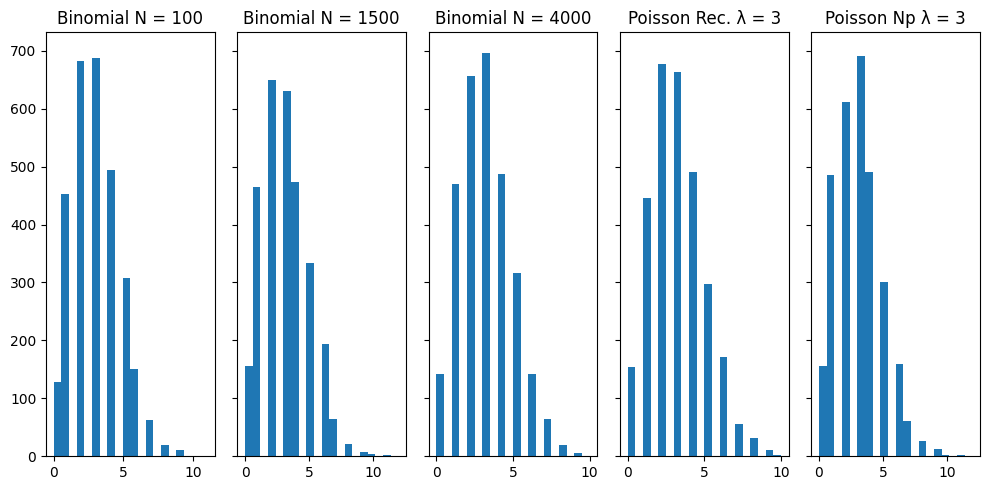

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

lmd = 3
M = 3000
lista_n = [100, 1500, 4000]
lista_dist = []

def amostraBinomialIngenua(n, M, p):
    amostra = []
    for i in range(M):
        uniforme = np.random.uniform(0, 1, size=n) # retorna um array de valores
        binomial = np.sum(uniforme < p)
        amostra.append(binomial)
    return amostra

def amostraPoissonRecursivo(M, lmd):
  amostra = []
  for _ in range(M):
    u = np.random.uniform(0,1)

    i = 0
    pi = np.exp((-lmd))
    F = pi
    while u > F:
      i+=1
      pi = (lmd/i) * pi
      F = F + pi
    amostra.append(i)
  return amostra

amostra_pois = amostraPoissonRecursivo(M, lmd)
amostra_pois_np = np.random.poisson(lmd, size=M)


for n in lista_n:
  pn = lmd/n
  lista_dist.append(amostraBinomialIngenua(n, M, pn))

fig, axs = plt.subplots(1, 5, sharey=True, tight_layout=True, figsize=(10, 5)) # https://matplotlib.org/stable/gallery/statistics/hist.html
axs[0].hist(lista_dist[0], bins=20)
axs[0].set(title="Binomial N = {}".format(lista_n[0]))

axs[1].hist(lista_dist[1], bins=20)
axs[1].set(title="Binomial N = {}".format(lista_n[1]))

axs[2].hist(lista_dist[2], bins=20)
axs[2].set(title="Binomial N = {}".format(lista_n[2]))

axs[3].hist(amostra_pois, bins=20)
axs[3].set(title="Poisson Rec. λ = {}".format(lmd))

axs[4].hist(amostra_pois_np, bins=20)
axs[4].set(title="Poisson Np λ = {}".format(lmd))

plt.show()

In [ ]:
import time as time
import pandas as pd
repeticoes = 20 # quantas amostrass serão geradas para, depois, calcular a média do tempo de execução
n_binomial = 3000
resultado = []

runtimes_poisson_inversao = []
runtimes_binomial_aprox = []

for _ in range(repeticoes):
  comeco = time.time()
  amostraPoissonRecursivo(M, lmd)
  runtimes_poisson_inversao.append(time.time() - comeco)

  comeco = time.time()
  amostraBinomialIngenua(n_binomial, M, (lmd/n_binomial))
  runtimes_binomial_aprox.append(time.time() - comeco)

resultado.append({
    "Lambda": lmd,
    "Media Poisson": np.mean(runtimes_poisson_inversao),
    "Media Binomial Aprox.": np.mean(runtimes_binomial_aprox)
})

df_resultado = pd.DataFrame(resultado)

print(df_resultado)

   Lambda  Media Poisson  Media Binomial Aprox.
0       3       0.017291               0.126598


De acordo com os resultados obtidos, temos as seguintes conclusões:

*   A aproximação binomial-poisson é bem consistente, e para valores pequenos de n, já demonstra distribuição similar a poisson
*   Os três métodos apresentam distribuição semelhante
*   Considerando uma média de 20 execuções, n = 3000 para a Binomial e uma amostra de tamanho M = 3000, ambos os métodos possuem tempo de execução semelhante, com uma diferença de aprox. 0.05s (Sendo a aprox. da binomial o mais rápido)



